## Setup

In [1]:
# import basic packages
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import PIL
import torch

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sumn2u/garbage-classification-v2")

print("Path to dataset files:", path)

/opt/anaconda3/envs/CLIP_env_312/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: /Users/lionellopenoni/.cache/kagglehub/datasets/sumn2u/garbage-classification-v2/versions/12


In [3]:
from datasets import load_dataset
dataset = load_dataset(path + "/standardized_384", split="train")

labels = dataset.features["label"].names
print(f"Labels: {labels}")
print(f"Number of images: {dataset.num_rows}")

Labels: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']
Number of images: 12259


In [4]:
# Load CLIP processor and model
from transformers import CLIPProcessor, CLIPModel

processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 56849.65it/s]


## Sample classification run

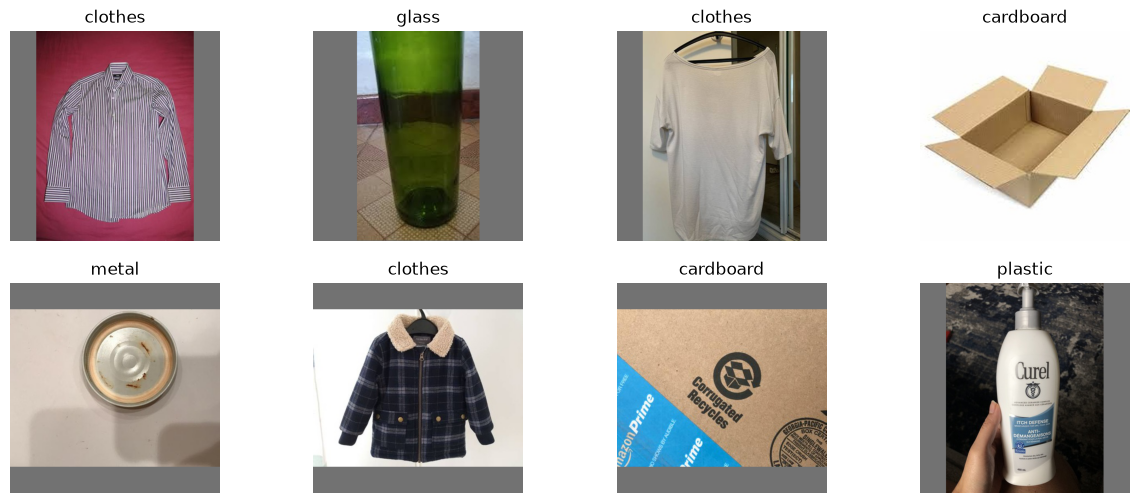

In [5]:
sample = dataset.shuffle(seed=42)[:8]
images = sample["image"]
true_labels = sample["label"]

plt.figure(figsize=(15, 6))
for i, image in enumerate(images):
        plt.subplot(2, int(len(images)/2), i + 1)
        plt.imshow(image)
        plt.title(labels[true_labels[i]]) # adding title to the images for more informative plot
        plt.axis('off') #elimitating axis in plot for a cleaner view

In [6]:
inputs = processor(images=images, text=labels, return_tensors="pt", padding=True)
outputs = model(**inputs)

logits_per_image = outputs.logits_per_image
probs = logits_per_image.softmax(dim=1)
predictions = probs.argmax(dim=1)

In [7]:
predicted_labels = [labels[id] for id in predictions]
predicted_labels

['clothes',
 'glass',
 'clothes',
 'cardboard',
 'cardboard',
 'clothes',
 'cardboard',
 'biological']

In [8]:
# Wrap the label prediction steps (above) into a function for quick use
from typing import List
def predict_labels(images: List, labels:List[str]=labels, processor=processor, model=model):
    """
    Process and predict the class of a set of images, given a set of possible labels. Especially designed for zero-shot classification.

    Parameters
    ----------
    images : List
        A list of images to be classified
    labels : List[str]
        A list of strings containing the possible classes
    processor
        The processor to be used to transform images and labels into numerical embeddings
    model
        The model to be used to predict class labels

    Returns
    -------
    predictions : List
        A list of the label indexes predicted for the list of input images
    predicted_labels : List
        A list of the labels predicted for the list of input images
    """
    
    inputs = processor(images=images, text=labels, return_tensors="pt", padding=True)
    outputs = model(**inputs)

    logits_per_image = outputs.logits_per_image
    probs = logits_per_image.softmax(dim=1)
    predictions = probs.argmax(dim=1).tolist()
    predicted_labels = [labels[id] for id in predictions]

    return predictions, predicted_labels


In [9]:
predict_labels(images)

([3, 4, 3, 2, 2, 3, 2, 1],
 ['clothes',
  'glass',
  'clothes',
  'cardboard',
  'cardboard',
  'clothes',
  'cardboard',
  'biological'])

## Predict on Dataset

In [10]:
from datasets import load_dataset
dataset = load_dataset(path + "/standardized_384", split="train")

labels = dataset.features["label"].names
print(f"Labels: {labels}")
print(f"Number of images: {dataset.num_rows}")

Labels: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']
Number of images: 12259


In [11]:
def count_observations(dataset):
    labels = dataset.features["label"].names
    label_counts = {label: dataset["label"].count(labels.index(label)) for label in labels}
    label_counts = pd.DataFrame.from_dict(label_counts, orient="index", columns=["count"]).reset_index(names="label")
    return label_counts

label_counts = count_observations(dataset)

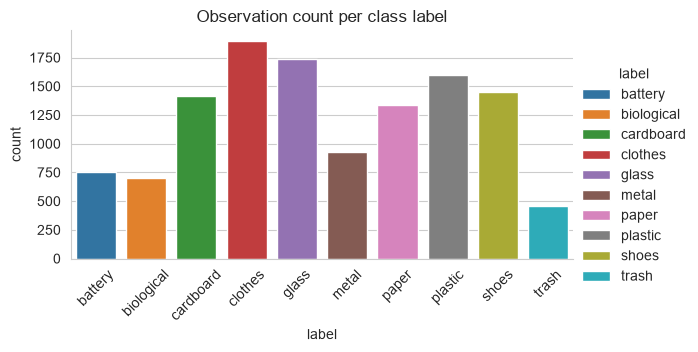

In [12]:
import seaborn as sns

sns.set_style("whitegrid")
sns.catplot(label_counts, x="label", y="count", kind="bar", hue="label", legend=True, height=3, aspect=2)
plt.xticks(rotation=45)
plt.title("Observation count per class label")
plt.show()

In [13]:
# Split dataset into train and test
data_split = dataset.train_test_split(test_size=0.2, shuffle=True, seed=42, stratify_by_column="label")
train = data_split["train"]
test = data_split["test"]
print("Train Split:\n", count_observations(train))
print("\nTest Split:\n", count_observations(test))

Train Split:
         label  count
0     battery    605
1  biological    559
2   cardboard   1129
3     clothes   1513
4       glass   1389
5       metal    744
6       paper   1069
7     plastic   1278
8       shoes   1159
9       trash    362

Test Split:
         label  count
0     battery    151
1  biological    140
2   cardboard    282
3     clothes    379
4       glass    347
5       metal    186
6       paper    267
7     plastic    319
8       shoes    290
9       trash     91


In [14]:
# process images in test split
from transformers import CLIPImageProcessor
image_processor = CLIPImageProcessor.from_pretrained("openai/clip-vit-base-patch32")

def preprocess_images(examples):
    images = examples["image"]
    inputs = image_processor(images, return_tensors="pt")
    examples["pixel_values"] = inputs["pixel_values"]
    return examples

test = test.map(preprocess_images, batched=True, remove_columns=["image"])

In [15]:
from transformers import AutoTokenizer
from transformers import CLIPModel
from torch.utils.data import DataLoader
def predict_processed_dataset(dataset=test, text=labels, tokenize_text=True):

    # encode text labels
    tokenizer = AutoTokenizer.from_pretrained("openai/clip-vit-base-patch32")
    if tokenize_text:
        text_inputs = tokenizer(text=text, return_tensors="pt", padding=True)
    else: text_inputs = text

    # instantiate model
    model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")

    # create DataLoader for processing in batches
    dataset.set_format("torch", columns=["pixel_values"], output_all_columns=True)
    loader = DataLoader(dataset, batch_size=32, num_workers=4) # type: ignore

    predictions = []

    for batch in loader:
        pixel_values = batch["pixel_values"]
        with torch.no_grad():
            output = model(**text_inputs, pixel_values=pixel_values)
        logits_per_image = output.logits_per_image
        probs = logits_per_image.softmax(dim=1)
        predictions.extend(probs.argmax(dim=1).tolist())

    return predictions

In [16]:
predictions = predict_processed_dataset(dataset=test, text=labels)

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 57497.78it/s]


In [17]:
# predictions
predicted_labels = [labels[id] for id in predictions]

# ground thruth
true_labels = list(test["label"])
true_labels_text = [labels[id] for id in true_labels]

## Evaluate Predictions

In [18]:
from typing import List
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

def evaluate_predictions(y_true : List, y_pred : List, target_names=labels):
    """Calculates and prints classification evaluation metrics accuracy, precision, recall, and f1-score and prints the classification report.
    
    Parameters
    ----------
    y_true : List
        List containing the true labels
    y_pred : List
        List containing the predicted labels
    target_names : List
        List of label names to be displayed in the classification report. Defaults to the variable "labels".

    Returns
    -------
    A dictionary with keys "accuracy", "precision", "recall", and "f1", containing the respective metric values
    """
    accuracy = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted")

    print(f"\n{"="*60}\nResults:    \n {"="*60}")
    print(f"Accuracy:       {accuracy:.4f}")
    print(f"Precision:      {precision:.4f}")
    print(f"Recall:         {recall:.4f}")
    print(f"F1:             {f1:.4f}")
    print(classification_report(y_true, y_pred, target_names=target_names, zero_division=0))

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }


In [19]:
metrics_dict = evaluate_predictions(true_labels_text, predicted_labels)


Results:    
Accuracy:       0.7072
Precision:      0.7246
Recall:         0.7072
F1:             0.6994
              precision    recall  f1-score   support

     battery       0.40      0.13      0.19       151
  biological       0.39      0.77      0.52       140
   cardboard       0.75      0.54      0.63       282
     clothes       0.99      0.98      0.99       379
       glass       0.93      0.71      0.80       347
       metal       0.55      0.53      0.54       186
       paper       0.54      0.87      0.67       267
     plastic       0.66      0.66      0.66       319
       shoes       0.99      0.99      0.99       290
       trash       0.10      0.07      0.08        91

    accuracy                           0.71      2452
   macro avg       0.63      0.63      0.61      2452
weighted avg       0.72      0.71      0.70      2452



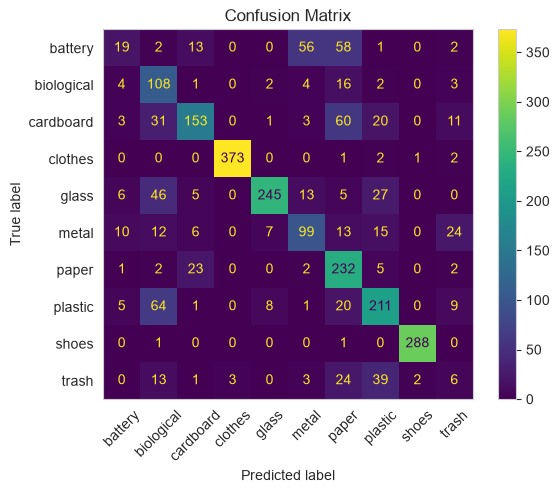

In [20]:
# Plot Confusion Matrix
from sklearn.metrics import ConfusionMatrixDisplay

def plot_conf_matrix(y_true, y_pred, title="Confusion Matrix"):
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, xticks_rotation=45)
    plt.title(title)
    plt.grid(False)
    plt.show()

plot_conf_matrix(true_labels_text, predicted_labels)

## Zero-Shot with prompt engineering

### Define prompt templates

In [21]:
# materials
material_labels = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic"]
material_templates = [
    "a photo of {label}.",
    "an object made of {label}.",
    "a close-up photo of {label} material."]

# wearables
wearable_labels = [
    "clothes",
    "shoes"]
wearable_templates = [
    "a photo of {label}.",
    "an image of {label}.",
    "a person's {label}.",
]

# biological
biological_templates = [
    "a photo of biological matter.",
    "an image of biological material.",
    "a photo of biological scraps.",
]

# battery
battery_templates = [
    "a photo of a battery.",
    "an image of a battery.",
    "a close-up photo of a battery.",
]

# trash
trash_templates = [
    "a photo of trash.",
    "an image of trash.",
    "a close-up photo of trash.",
]

### Fill templates and create collections for prompts

In [22]:
templates_dict = {}
for material in material_labels:
    templates_dict[material] = [template.format(label=material) for template in material_templates]
for wearable in wearable_labels:
    templates_dict[wearable] = [template.format(label=wearable) for template in material_templates]
templates_dict["biological"] = biological_templates
templates_dict["battery"] = battery_templates
templates_dict["trash"] = trash_templates

# store lists of labels and prompts
prompt_labels = list(templates_dict.keys())
prompts = []
for set in templates_dict.values():
    prompts.extend(set)


### Make predicitons

In [23]:
predictions_prompts = predict_processed_dataset(dataset=test, text=prompts)

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 43450.71it/s]


In [24]:
# turn prediced prompts into predicted labels
predictions_np = np.array(predictions_prompts)
predictions_np = np.floor(predictions_np/3)  # Divide by 3 because there are 3 prompts per label
predicted_labelIds = list(map(int, predictions_np.tolist())) # Store as integers

# predictions
predicted_labels = [prompt_labels[id] for id in predicted_labelIds]

# ground thruth
true_labels = list(test["label"])
true_labels_text = [labels[id] for id in true_labels]

### Evaluate


Results:    
Accuracy:       0.7492
Precision:      0.7819
Recall:         0.7492
F1:             0.7474
              precision    recall  f1-score   support

     battery       0.57      1.00      0.72       151
  biological       0.58      0.87      0.70       140
   cardboard       0.77      0.56      0.65       282
     clothes       0.92      0.99      0.96       379
       glass       0.91      0.71      0.80       347
       metal       0.81      0.31      0.45       186
       paper       0.82      0.72      0.77       267
     plastic       0.64      0.72      0.68       319
       shoes       0.98      0.98      0.98       290
       trash       0.11      0.16      0.13        91

    accuracy                           0.75      2452
   macro avg       0.71      0.70      0.68      2452
weighted avg       0.78      0.75      0.75      2452



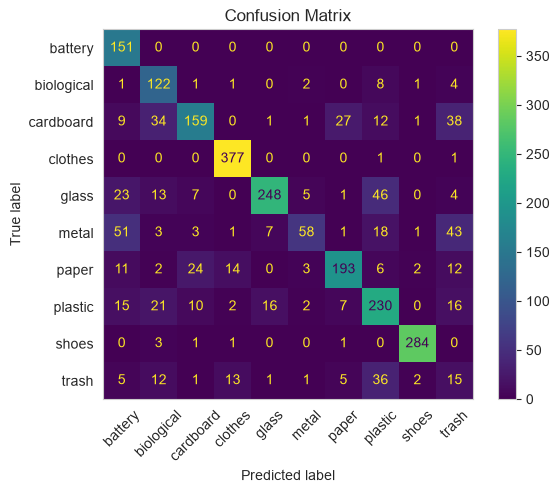

In [25]:
metrics_dict_prompts = evaluate_predictions(true_labels_text, predicted_labels)
plot_conf_matrix(true_labels_text, predicted_labels)

## Zero-Shot with prompt engineering and averaged prompt embeddings

### Compute class embeddings from mean of prompt embeddings per label

In [ ]:
from transformers import CLIPTextModelWithProjection
from transformers import AutoTokenizer
from transformers import logging as hf_logging
hf_logging.set_verbosity_error()

text_model = CLIPTextModelWithProjection.from_pretrained("openai/clip-vit-base-patch32")
tokenizer = AutoTokenizer.from_pretrained("openai/clip-vit-base-patch32")

def compute_class_embedding(label):
    inputs = tokenizer(text=templates_dict[label], return_tensors="pt", padding=True)

    with torch.no_grad():
        outputs = text_model(**inputs)
    text_embeds = outputs.text_embeds
    text_embeds = text_embeds / text_embeds.norm(dim=-1, keepdim=True)
    class_embedding = text_embeds.mean(dim=0)
    class_embedding = class_embedding / class_embedding.norm(dim=-1, keepdim=True)

    return class_embedding

# Compute class embeddings and store as tensor
class_embeddings = torch.stack(
    [compute_class_embedding(label) for label in labels]
)

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 42176.40it/s]


### Compute image embeddings

In [27]:
from transformers import CLIPVisionModelWithProjection
from torch.utils.data import DataLoader

vision_model = CLIPVisionModelWithProjection.from_pretrained("openai/clip-vit-base-patch32")

# create DataLoader for processing in batches
test.set_format("torch", columns=["pixel_values"], output_all_columns=True)
loader = DataLoader(test, batch_size=32, num_workers=4) # type: ignore

all_embeds = []

for batch in loader:
    with torch.no_grad():
        outputs = vision_model(batch["pixel_values"])
    image_embeds = outputs.image_embeds
    image_embeds = image_embeds / image_embeds.norm(dim=-1, keepdim=True)

    all_embeds.append(image_embeds)

image_embeddings = torch.cat(all_embeds)


Loading weights: 100%|██████████| 200/200 [00:00<00:00, 41519.54it/s]


### Compute Similarity and make predictions

In [28]:
from transformers import CLIPModel
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")

# image_embeddings: shape (2452, 512) — from CLIPVisionModelWithProjection, normalized
# class_embeddings: shape (10, 512) — from CLIPTextModelWithProjection, normailzed

logit_scale = model.logit_scale.exp()
logits_per_image = logit_scale * image_embeddings @ class_embeddings.T  # shape (batch_size, num_labels)

probs = logits_per_image.softmax(dim=-1)
predictions = probs.argmax(dim=-1)

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 47150.97it/s]


In [29]:
# predictions
predicted_labels = [labels[id] for id in predictions]

# ground thruth
true_labels = list(test["label"])
true_labels_text = [labels[id] for id in true_labels]

### Evaluate Predictions


Results:    
Accuracy:       0.7659
Precision:      0.7977
Recall:         0.7659
F1:             0.7660
              precision    recall  f1-score   support

     battery       0.62      1.00      0.77       151
  biological       0.65      0.81      0.72       140
   cardboard       0.79      0.56      0.65       282
     clothes       0.93      1.00      0.96       379
       glass       0.92      0.74      0.82       347
       metal       0.85      0.36      0.51       186
       paper       0.83      0.77      0.80       267
     plastic       0.64      0.77      0.70       319
       shoes       0.98      0.99      0.98       290
       trash       0.12      0.19      0.14        91

    accuracy                           0.77      2452
   macro avg       0.73      0.72      0.71      2452
weighted avg       0.80      0.77      0.77      2452



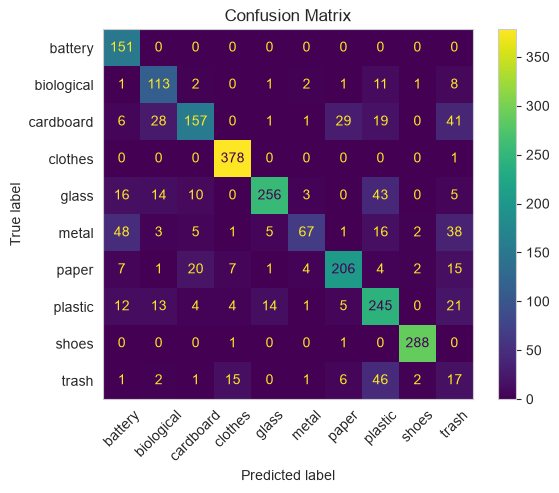

In [30]:
# Print metric scores
metrics_dict_mean_embeddings = evaluate_predictions(true_labels_text, predicted_labels)

# Plot Confusion Matrix
plot_conf_matrix(true_labels_text, predicted_labels)